# The impact substitute: what the first-innings deployments were, and how teams built around it

**The question, given the deployment analysis.** Teams moved the impact substitute into the first innings in 2024 (26 to 43 deployments) and the timing within an innings did not change. A watcher's model of why goes like this: a side bowling first names its strongest bowling eleven and brings the extra batter in during its fielding innings, a warm-up for the chase; a side batting first names its strongest batting eleven, knowing a bowler can come in later, and so bats with depth, which should show as more powerplay aggression. This notebook tests each part of that model against the record.

**What this notebook does.**
1. Classifies every impact deployment by who made it (the side that batted first or the side that bowled first), the innings, the discipline the side was engaged in at entry, and the incoming and outgoing players' roles, and reads the first-innings deployments against the warm-up model.
2. For batting-first sides' in-innings substitutions, asks whether the swap followed the outgoing batter's dismissal, how long after, and whether the incoming player then bowled; and which teams did it.
3. Counts roles in each team-match's initial eleven and compares batting-first with bowling-first elevens, per season, with the change across seasons.
4. Compares each team's powerplay attempt share and gear-up when batting first with the same team's when chasing, per season, and the change in that gap.
5. Reads death-overs scoring of batting-first innings by whether the side ran a mid-innings swap, at matched wickets down.

**How to read this notebook.** Player *roles* come from each player's two-season record: a bowler bowled at least 60 legal balls and faced fewer, a batter the reverse, an all-rounder both, thin neither. The *initial eleven* is the named eleven before the substitute entered. *Attempt share* is the share of faced powerplay balls played with an aggressive shot; *gear-up* is the powerplay run rate minus the team's own middle-overs run rate. Intervals are 95% percentile intervals on shared match draws. A chase carries its own target pressure, so the batting-first against chasing contrast is descriptive, and the death-scoring table is selected on wickets by construction.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Code lives in `scripts/impact_substitute_mechanics/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from impact_substitute_mechanics import deployment_mechanics as dm

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "impact_substitute_mechanics"
SEED = settings.seed("global")
N_ITER = settings.n_resamples
ROLE_MIN_BALLS = int(settings.section("impact_substitute_mechanics")["role_min_balls"])
PRODUCER = "impact_substitute_mechanics.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}  role floor={ROLE_MIN_BALLS} balls")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000  role floor=60 balls


## Data

The cleaned frame, the impact-player table (276 impact-player events) and the match rosters, both built in `exploration.ipynb`.

In [2]:
df = scb.load_cleaned_dataset(str(settings.data_path("cleaned_dataset")))
impact = pd.read_parquet(settings.data_path("impact_player_table"))
rosters = pd.read_parquet(settings.data_path("match_rosters"))
print(f"balls={len(df):,}  impact events={int((impact['reason'] == 'impact_player').sum())}  roster rows={len(rosters)}")
EXTRA = {"n_resamples": N_ITER, "role_min_balls": ROLE_MIN_BALLS}

balls=34,967  impact events=276  roster rows=3467


## Player roles from the two-season record

Found: 89 bowlers, 83 batters, 28 all-rounders and 71 thin players (fewer than 60 balls either way), 271 players in all.

In [3]:
roles = dm.classify_player_roles(df, ROLE_MIN_BALLS)
results_io.write_table(roles, settings, ANALYSIS, "player_roles", SEED, PRODUCER, EXTRA)
print(roles["role"].value_counts().to_dict())
roles.sort_values("balls_bowled", ascending=False).head(8)

{'bowler': 89, 'batter': 83, 'thin': 71, 'all_rounder': 28}


,player_id,balls_faced,balls_bowled,role,name
236,430246,0,665,bowler,Yuzvendra Chahal
134,793463,131,664,all_rounder,Rashid Khan
47,326016,76,648,all_rounder,Bhuvneshwar Kumar
137,822553,2,629,bowler,Tushar Deshpande
151,940973,10,624,bowler,Mohammed Siraj
2,26421,125,624,all_rounder,Ravichandran Ashwin
17,234675,320,624,all_rounder,Ravindra Jadeja
15,230558,295,618,all_rounder,Sunil Narine


## Who deployed in the first innings, and whom

Every deployment classified, then: counts by side and innings; first-innings deployments by side and incoming role, and by outgoing role; the over of entry; and for bowling-first sides' first-innings substitutes, whether the incoming player batted in the match.

In [4]:
events = dm.classify_deployments(impact, df, roles)
summary = dm.deployment_summary(events)
results_io.write_table(events, settings, ANALYSIS, "deployments_classified", SEED, PRODUCER, EXTRA)
for name, table in summary.items():
    results_io.write_table(table, settings, ANALYSIS, f"deployments_{name}", SEED, PRODUCER, EXTRA)
    print(name)
    display(table.round(3))

by_side_innings


innings,season,side,1,2
0,2023,batted_first,9,64
1,2023,bowled_first,17,49
2,2024,batted_first,26,44
3,2024,bowled_first,17,50


first_innings_in_roles


in_role,season,side,all_rounder,batter,bowler,thin
0,2023,batted_first,1,2,5,1
1,2023,bowled_first,0,15,1,1
2,2024,batted_first,4,8,8,6
3,2024,bowled_first,1,13,0,3


first_innings_out_roles


out_role,season,side,all_rounder,batter,bowler,thin
0,2023,batted_first,0,9,0,0
1,2023,bowled_first,0,1,15,1
2,2024,batted_first,2,23,0,1
3,2024,bowled_first,0,2,14,1


first_innings_entry_over


,season,side,events,median_over,mean_over,share_in_death
0,2023,batted_first,9,15.0,15.556,0.444
1,2023,bowled_first,17,18.0,17.235,0.824
2,2024,batted_first,26,17.0,15.115,0.538
3,2024,bowled_first,17,19.0,18.412,1.000


bowled_first_first_innings_subs


,season,events,in_player_batted,in_player_bowled
0,2023,17,0.647,0.0
1,2024,17,0.706,0.0


In [5]:
events[events["innings"] == 1].groupby(["season", "side", "discipline_at_entry", "in_role", "out_role"]).size().rename("events").reset_index()

,season,side,discipline_at_entry,in_role,out_role,events
0,2023,batted_first,batting,all_rounder,batter,1
1,2023,batted_first,batting,batter,batter,2
2,2023,batted_first,batting,bowler,batter,5
3,2023,batted_first,batting,thin,batter,1
4,2023,bowled_first,fielding,batter,batter,1
5,2023,bowled_first,fielding,batter,bowler,13
6,2023,bowled_first,fielding,batter,thin,1
7,2023,bowled_first,fielding,bowler,bowler,1
8,2023,bowled_first,fielding,thin,bowler,1
9,2024,batted_first,batting,all_rounder,batter,4


The warm-up half of the model is right and did not change. Bowling-first sides made 17 first-innings substitutions in each season, a batter for a bowler in 13 of 17 and 10 of 17, entering at a median of over 18 to 19 (82% at the death in 2023, every one in 2024), and the incoming batter went on to bat in about two thirds of those matches. That is a fielding side bringing its chase batter on for the last few overs.

The 2024 rise is entirely the other side. Batting-first sides substituted during their own batting innings 9 times in 2023 and 26 times in 2024, entering around over 15 to 17, and the outgoing player was a batter in every case but three. What came in changed: in 2023 mostly a bowler for the spent batter (5 of 9); in 2024 a batter or all-rounder more often than a bowler (12 against 8, with 6 thin players). The batting-first side was not converting a batter into a bowler; it was adding a batter.

## Batting-first swaps: triggered by a dismissal?

For those in-innings substitutions: whether the outgoing player had already been dismissed before the entry ball, the lag between dismissal and entry in balls, whether the incoming player bowled in the second innings, and the role mix; then the same swaps by team and season; then every swap listed.

In [6]:
swaps = dm.dismissal_linked_swaps(events, df)
swap_summary = dm.dismissal_linked_summary(swaps)
by_team = dm.swaps_by_team(events)
results_io.write_table(swaps, settings, ANALYSIS, "batting_first_swaps", SEED, PRODUCER, EXTRA)
results_io.write_table(swap_summary, settings, ANALYSIS, "batting_first_swaps_summary", SEED, PRODUCER, EXTRA)
results_io.write_table(by_team, settings, ANALYSIS, "batting_first_swaps_by_team", SEED, PRODUCER, EXTRA)
display(swap_summary.round(3))
display(by_team)
swaps.sort_values(["season", "deploy_ball_id"]).round(2)

,season,swaps,out_dismissed_before_entry,median_balls_after_dismissal,within_one_over,in_bowled_second_innings,in_all_rounder,in_batter,in_bowler,in_thin
0,2023,9,1.0,22.0,0.222,0.556,1,2,5,1
1,2024,26,1.0,35.0,0.038,0.346,4,8,8,6


season,team,2023,2024
9,Sunrisers Hyderabad,0,7
8,Royal Challengers Bengaluru,2,4
1,Delhi Capitals,0,3
4,Lucknow Super Giants,2,3
0,Chennai Super Kings,0,2
2,Gujarat Titans,0,2
6,Punjab Kings,1,2
3,Kolkata Knight Riders,2,1
5,Mumbai Indians,0,1
7,Rajasthan Royals,2,1


,season,match_id,team,player_out,out_role,player_in,in_role,deploy_over,deploy_ball_id,out_dismissed_before_entry,dismissal_ball_id,balls_after_dismissal,in_bowled_second_innings
7,2023,1359522,Rajasthan Royals,YBK Jaiswal,batter,R Parag,batter,9,8.01,True,5.01,18,False
1,2023,1359488,Punjab Kings,P Simran Singh,batter,Sikandar Raza,all_rounder,9,8.06,True,0.01,53,False
8,2023,1359528,Royal Challengers Bengaluru,MK Lomror,batter,KM Jadhav,thin,15,14.01,True,13.04,3,False
3,2023,1359494,Royal Challengers Bengaluru,MK Lomror,batter,Anuj Rawat,batter,15,14.03,True,12.03,12,False
5,2023,1359502,Kolkata Knight Riders,VR Iyer,batter,AS Roy,bowler,15,14.05,True,3.03,68,True
6,2023,1359521,Kolkata Knight Riders,JJ Roy,batter,AS Roy,bowler,18,17.04,True,4.06,76,True
4,2023,1359495,Lucknow Super Giants,KR Mayers,batter,K Gowtham,bowler,19,18.05,True,7.04,67,True
2,2023,1359491,Rajasthan Royals,JC Buttler,batter,A Zampa,bowler,20,19.06,True,16.02,22,True
0,2023,1359477,Lucknow Super Giants,A Badoni,batter,K Gowtham,bowler,20,19.08,True,19.07,1,True
12,2024,1422132,Mumbai Indians,Naman Dhir,batter,D Brevis,thin,2,1.01,True,0.06,1,False


Every one of the 35 swaps came after the outgoing batter had been dismissed, but not on the dismissal: the median lag was 22 balls in 2023 and 35 in 2024, and only 4% of the 2024 swaps came within an over (22% in 2023). The incoming player bowled in the second innings in 56% of the 2023 swaps and 35% of the 2024 ones. So the 2024 pattern is not "convert the spent batter into a bowler straight away"; it is a fresh batter brought in some overs after a dismissal, a twelfth batting option used mid-innings. Sunrisers ran it seven times in 2024 having not done it in 2023, Bengaluru four, Delhi and Lucknow three; the aggressive wing of the powerplay dispersion (Sunrisers, Delhi, Bengaluru) accounts for 14 of the 26.

## Eleven composition by batting order

Role counts in each team-match's initial eleven, batting-first against bowling-first teams per season, the gap with a match bootstrap interval, and the change in the gap across seasons. If batting-first sides in 2024 named eight batters expecting a bowler later, the batting-first elevens should have gained a batter and lost a bowler relative to 2023.

In [7]:
elevens = dm.initial_elevens(rosters, df, roles)
composition = dm.eleven_composition_contrast(elevens, settings, SEED, N_ITER)
results_io.write_table(elevens, settings, ANALYSIS, "initial_elevens", SEED, PRODUCER, EXTRA)
results_io.write_table(composition, settings, ANALYSIS, "eleven_composition_contrast", SEED, PRODUCER, EXTRA)
display(elevens.groupby(["season", "batted_first"])[["batter", "bowler", "all_rounder", "thin", "recognised_bowlers", "recognised_batters"]].mean().round(2))
composition.round(3)

batter  bowler  all_rounder  thin  recognised_bowlers  recognised_batters
season batted_first                                                                           
2023   False           4.69    3.70         2.19  0.43                5.89                6.88
       True            5.43    3.00         2.09  0.47                5.09                7.53
2024   False           4.93    3.59         2.04  0.44                5.63                6.97
       True            5.27    3.11         2.28  0.34                5.39                7.55

,metric,season,mean_batting_first,mean_bowling_first,gap_batting_minus_bowling_first,gap_low,gap_high,p_gap_positive
0,recognised_bowlers,2023,5.095,5.892,-0.797,-1.068,-0.527,0.000
1,recognised_bowlers,2024,5.394,5.634,-0.239,-0.648,0.169,0.122
2,recognised_bowlers,2024 minus 2023,NaN,NaN,0.558,0.072,1.062,0.987
3,recognised_batters,2023,7.527,6.878,0.649,0.338,0.959,1.000
4,recognised_batters,2024,7.549,6.972,0.577,0.268,0.901,1.000
5,recognised_batters,2024 minus 2023,NaN,NaN,-0.071,-0.524,0.376,0.377
6,bowler,2023,3.000,3.703,-0.703,-1.014,-0.392,0.000
7,bowler,2024,3.113,3.592,-0.479,-0.775,-0.197,0.000
8,bowler,2024 minus 2023,NaN,NaN,0.224,-0.201,0.650,0.851
9,batter,2023,5.432,4.689,0.743,0.459,1.027,1.000


Batting-first elevens carry more batters and fewer bowlers than bowling-first elevens in both seasons (2023: +0.74 batters and −0.70 bowlers, both clear; 2024: +0.34 and −0.48). But the gap narrowed rather than widened: the recognised-bowler gap went from −0.80 to −0.24, a change of +0.56 with an interval of +0.07 to +1.06, and the batter gap fell by 0.41 (interval −0.87 to +0.06, P 0.04). In 2024 a batting-first eleven looked more like a bowling-first one, not less. That is the prediction failing, and it fits the swap finding: a side that plans to add a batter in play does not need to name eight; it names a balanced eleven and adds the batter when the innings asks for one.

## Batting first against chasing, within team

Each team's powerplay attempt share and gear-up batting first and chasing, per season; the mean team gap with an interval; and the change in the mean gap. Descriptive: a chase has its own target pressure.

In [8]:
contrast = dm.bat_first_vs_chase_contrast(df, settings, SEED, N_ITER)
results_io.write_table(contrast["summary"], settings, ANALYSIS, "bat_first_vs_chase_summary", SEED, PRODUCER, EXTRA)
results_io.write_table(contrast["per_team"], settings, ANALYSIS, "bat_first_vs_chase_by_team", SEED, PRODUCER, EXTRA)
display(contrast["summary"].round(4))
contrast["per_team"].round(4)

,metric,season,batting_first_mean_over_teams,chasing_mean_over_teams,mean_team_gap,gap_low,gap_high,p_gap_positive
0,attempt_share,2023,0.1353,0.1638,-0.0285,-0.0505,-0.0071,0.0054
1,gear_up,2023,0.3134,0.1359,0.1775,-0.5821,0.9314,0.6822
2,attempt_share,2024,0.1371,0.1635,-0.0265,-0.0508,-0.0028,0.0144
3,gear_up,2024,0.1140,1.0255,-0.9116,-1.8039,-0.0207,0.0221
4,attempt_share,2024 minus 2023,NaN,NaN,0.0020,-0.0304,0.0343,0.5517
5,gear_up,2024 minus 2023,NaN,NaN,-1.0890,-2.2695,0.0691,0.0326


,season,team,attempt_share_batting_first,attempt_share_chasing,gear_up_batting_first,gear_up_chasing,attempt_share_gap,gear_up_gap
0,2023,Chennai Super Kings,0.1288,0.1475,-0.1358,1.3704,-0.0186,-1.5062
1,2023,Delhi Capitals,0.1215,0.2117,0.5111,0.8086,-0.0901,-0.2975
2,2023,Gujarat Titans,0.1557,0.1550,-0.3681,0.3591,0.0007,-0.7271
3,2023,Kolkata Knight Riders,0.1294,0.2063,-0.6190,-0.6587,-0.0769,0.0397
4,2023,Lucknow Super Giants,0.1367,0.1690,-0.9603,0.4514,-0.0322,-1.4117
5,2023,Mumbai Indians,0.1667,0.1911,0.6574,-0.1833,-0.0245,0.8407
6,2023,Punjab Kings,0.1284,0.1833,0.7469,-0.0222,-0.0549,0.7691
7,2023,Rajasthan Royals,0.1383,0.1230,2.5079,-0.3028,0.0153,2.8107
8,2023,Royal Challengers Bengaluru,0.1173,0.1333,0.3889,0.9333,-0.0160,-0.5444
9,2023,Sunrisers Hyderabad,0.1304,0.1181,0.4048,-1.3968,0.0123,1.8016


Batting first does not license powerplay risk; if anything the reverse. Teams attacked *less* in the powerplay when batting first than when chasing, by 2.9 points of attempt share in 2023 (interval −5.1 to −0.7) and 2.7 in 2024 (−5.1 to −0.3), with no change between seasons (+0.2, P 0.55). Gear-up showed no gap in 2023 (+0.18, P 0.68) and a large one the other way in 2024: chasing sides geared up 0.91 runs per over more than batting-first sides (interval −1.80 to −0.02), and the change of −1.09 (interval −2.27 to +0.07, P 0.03) leans hard toward chasing innings having become the more aggressive powerplay. The depth story predicted the opposite. What the chase brings is a known target, and in 2024 chasing sides went at the powerplay harder than sides setting one.

## Death scoring of batting-first innings, by whether the side ran the swap

Batting-first innings per season: death run rate with and without a mid-innings swap, overall and within bands of wickets down entering the death, with innings counts. The swap follows a dismissal, so swap innings are selected on wickets; the banded rows are the like-for-like read.

In [9]:
death_by_swap = dm.death_scoring_by_swap(df, events, settings)
results_io.write_table(death_by_swap, settings, ANALYSIS, "death_scoring_by_swap", SEED, PRODUCER, EXTRA)
death_by_swap.round(3)

,season,wkts_band,swap_in_innings,innings,death_run_rate,mean_wkts_before_death
0,2023,all,False,65,10.637,3.431
1,2023,all,True,9,8.433,5.889
2,2024,all,False,45,11.632,3.267
3,2024,all,True,26,9.212,5.462
4,2023,0-2,False,17,11.106,1.529
5,2023,3-4,False,31,10.729,3.548
6,2023,3-4,True,3,9.667,4.000
7,2023,5+,False,17,10.000,5.118
8,2023,5+,True,6,7.816,6.833
9,2024,0-2,False,10,11.960,1.800


Swap innings entered the death with far more wickets down (5.5 to 5.9 against 3.3 to 3.4), so the selection is as expected, and they scored less at the death overall (8.4 against 10.6 in 2023, 9.2 against 11.6 in 2024). At matched wickets the gap remains: in the five-or-more band in 2024, 8.7 runs per over over 20 swap innings against 11.0 over 7 without; in the three-to-four band, 11.0 against 11.7. There is no sign that the added batter was depth spent at the death; the swap marks an innings that had lost its shape. The death run-rate rise seen elsewhere is not this mechanism.

## What the added batter did

For each batting-first in-innings swap: the incoming player's own batting in that innings (balls, runs, strike rate, death balls) beside the rest of the innings' batters after the entry ball, and the season summary. A table to read, not a test.

In [10]:
contribution = dm.substitute_contribution(swaps, df, events, settings)
contribution_summary = dm.substitute_contribution_summary(contribution)
results_io.write_table(contribution, settings, ANALYSIS, "substitute_contribution", SEED, PRODUCER, EXTRA)
results_io.write_table(contribution_summary, settings, ANALYSIS, "substitute_contribution_summary", SEED, PRODUCER, EXTRA)
display(contribution_summary.round(2))
contribution.round(1)

,season,swaps,sub_batted_share,sub_balls_total,sub_runs_total,sub_death_balls_total,others_balls_after_entry_total,others_runs_after_entry_total,sub_strike_rate_pooled,others_strike_rate_pooled,sub_share_of_balls_after_entry
0,2023,9,1.00,56,57.0,36,197,220.0,101.79,111.68,0.22
1,2024,26,0.77,152,171.0,79,676,904.0,112.50,133.73,0.18


,season,match_id,team,player_in,in_role,deploy_over,sub_batted,sub_balls,sub_runs,sub_strike_rate,sub_death_balls,others_balls_after_entry,others_runs_after_entry,others_strike_rate_after_entry
0,2023,1359477,Lucknow Super Giants,K Gowtham,bowler,20,True,1,6.0,600.0,1,0,0.0,NaN
1,2023,1359488,Punjab Kings,Sikandar Raza,all_rounder,9,True,6,5.0,83.3,0,61,72.0,118.0
2,2023,1359491,Rajasthan Royals,A Zampa,bowler,20,True,1,1.0,100.0,1,0,0.0,NaN
3,2023,1359494,Royal Challengers Bengaluru,Anuj Rawat,batter,15,True,22,15.0,68.2,18,12,20.0,166.7
4,2023,1359495,Lucknow Super Giants,K Gowtham,bowler,19,True,2,1.0,50.0,2,6,6.0,100.0
5,2023,1359502,Kolkata Knight Riders,AS Roy,bowler,15,True,1,0.0,0.0,0,31,29.0,93.5
6,2023,1359521,Kolkata Knight Riders,AS Roy,bowler,18,True,7,13.0,185.7,7,8,7.0,87.5
7,2023,1359522,Rajasthan Royals,R Parag,batter,9,True,6,4.0,66.7,0,53,45.0,84.9
8,2023,1359528,Royal Challengers Bengaluru,KM Jadhav,thin,15,True,10,12.0,120.0,7,26,41.0,157.7
9,2024,1422120,Delhi Capitals,Abishek Porel,batter,18,True,10,32.0,320.0,10,7,2.0,28.6


The added batter was a passenger. In 2023 all nine substitutes batted, facing 22% of the balls after entry at a strike rate of 102 against 112 for the other batters. In 2024 six of the 26 never batted at all, the ones who did faced 18% of the balls after entry, and their pooled strike rate was 112 against 134 for the rest of the innings. One exception (Abishek Porel, 32 off 10 for Delhi) is the only case where the substitute did the scoring. So the mid-innings swap added a batter who mostly did not bat, and when he did, batted more slowly than the batters already there: insurance against running out of wickets, not depth to spend.

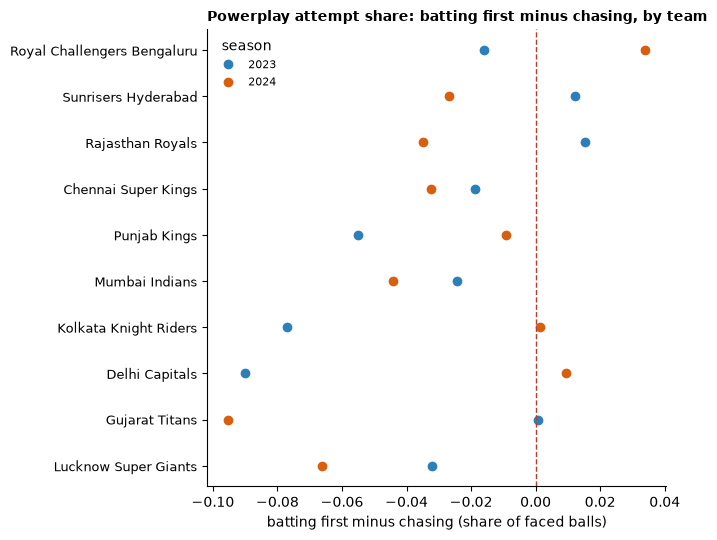

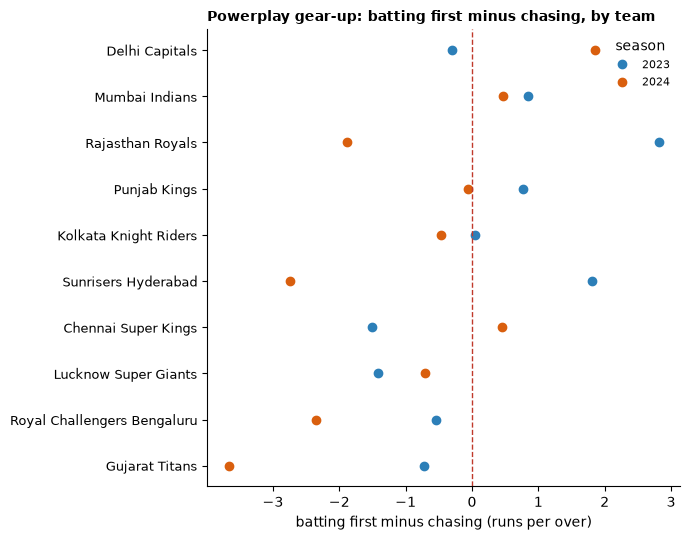

In [11]:
fig = dm.plot_team_gaps(contrast["per_team"], "attempt_share", "share of faced balls", "Powerplay attempt share: batting first minus chasing, by team")
results_io.write_figure(fig, settings, ANALYSIS, "attempt_share_gap_by_team", SEED, PRODUCER)
plt.show()
fig = dm.plot_team_gaps(contrast["per_team"], "gear_up", "runs per over", "Powerplay gear-up: batting first minus chasing, by team")
results_io.write_figure(fig, settings, ANALYSIS, "gear_up_gap_by_team", SEED, PRODUCER)
plt.show()

## Does the target explain the chase powerplay?

Chasing sides attacked the powerplay harder than sides batting first in both seasons, and in 2024 their gear-up jumped. First-innings totals were higher in 2024, so the candidate explanation is the target. One row per chasing innings: target, powerplay attempt share, powerplay run rate, gear-up (innings with at least 24 middle-overs balls). First the binned read by target band and season; then, per metric, a linear model with the target centred at 180 and a season term, under the match bootstrap: the response per run of target, the season difference at a common target of 180, the change in the response, and the raw season difference beside it. If the season difference at a common target shrinks to nothing, the target explains the change.

In [12]:
from impact_substitute_mechanics import chase_target_response as ctr

chases = ctr.chase_innings_table(df, settings)
binned = ctr.binned_by_target(chases)
response = ctr.target_response(chases, settings, SEED, N_ITER)
results_io.write_table(chases, settings, ANALYSIS, "chase_innings", SEED, PRODUCER, EXTRA)
results_io.write_table(binned, settings, ANALYSIS, "chase_by_target_band", SEED, PRODUCER, EXTRA)
results_io.write_table(response["coefficients"], settings, ANALYSIS, "chase_target_response", SEED, PRODUCER,
                       {**EXTRA, "mean_target": response["mean_target"]})
print("mean target by season:", response["mean_target"])
display(binned.round(3))
response["coefficients"].round(4)

mean target by season: {2023: 183.91780821917808, 2024: 190.6056338028169}


,season,target_band,innings,mean_target,attempt_share,run_rate,gear_up
0,2023,under 160,15,139.267,0.131,8.033,1.240
1,2023,160 to 189,26,176.462,0.178,8.404,0.596
2,2023,190 and over,32,210.906,0.174,8.375,-0.799
3,2024,under 160,12,137.667,0.156,9.306,2.033
4,2024,160 to 189,25,173.240,0.142,9.140,0.863
5,2024,190 and over,34,222.059,0.172,9.750,0.387


,metric,term,estimate,ci_low,ci_high,p_positive,n_innings,target_centre
0,attempt_share,intercept_at_180,0.1648,0.1494,0.1808,1.0000,144,180.0
1,attempt_share,per_run_of_target,0.0005,-0.0000,0.0009,0.9665,144,180.0
2,attempt_share,season_difference_at_180,-0.0133,-0.0397,0.0114,0.1406,144,180.0
3,attempt_share,change_in_target_response,0.0002,-0.0006,0.0010,0.7029,144,180.0
4,attempt_share,raw_season_difference,-0.0078,-0.0334,0.0168,0.2706,144,180.0
5,pp_run_rate,intercept_at_180,8.2751,7.8074,8.7564,1.0000,144,180.0
6,pp_run_rate,per_run_of_target,0.0102,-0.0065,0.0263,0.8871,144,180.0
7,pp_run_rate,season_difference_at_180,1.0227,0.2522,1.7853,0.9957,144,180.0
8,pp_run_rate,change_in_target_response,0.0051,-0.0180,0.0281,0.6721,144,180.0
9,pp_run_rate,raw_season_difference,1.1450,0.4156,1.8919,0.9992,144,180.0


The target does not explain it. Chase powerplay run rate rose 1.15 runs per over raw (interval +0.4 to +1.9) and 1.02 at a common target of 180 (interval +0.3 to +1.8); the response to the target itself is small (+0.01 runs per over per run of target, P 0.89). The binned read says the same: 2024 chasing sides scored faster in the powerplay at every target band, 9.3 against 8.0 under 160 and 9.8 against 8.4 at 190 and over. Attempt share is flat against the target and across seasons. Gear-up falls with the target (−0.023 runs per over per run, interval clears zero) because a big chase keeps the middle overs fast too, so the powerplay stands out less; the season difference in gear-up survives adjustment (+0.67 at a common target, P 0.93, against +0.70 raw). Chasing sides in 2024 went at the powerplay harder whatever they were chasing. That is a change of approach, not a response to bigger totals, and it belongs beside the batting-first finding: in 2024 the chase, not the innings with depth, was where the powerplay aggression moved.

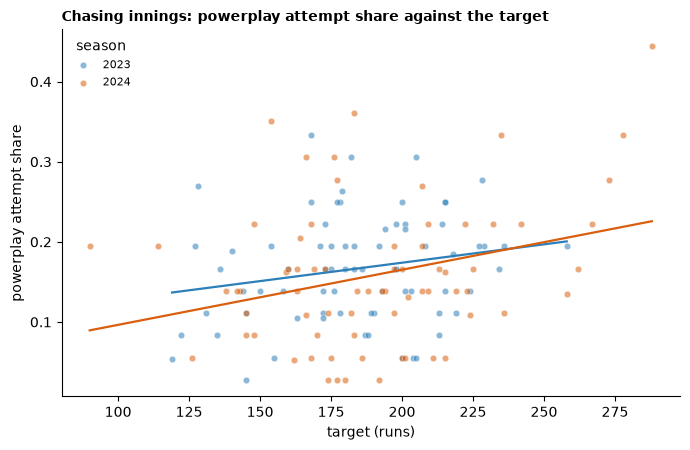

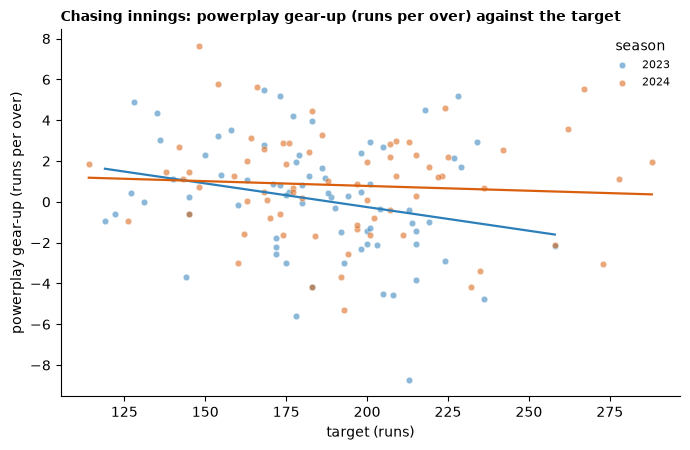

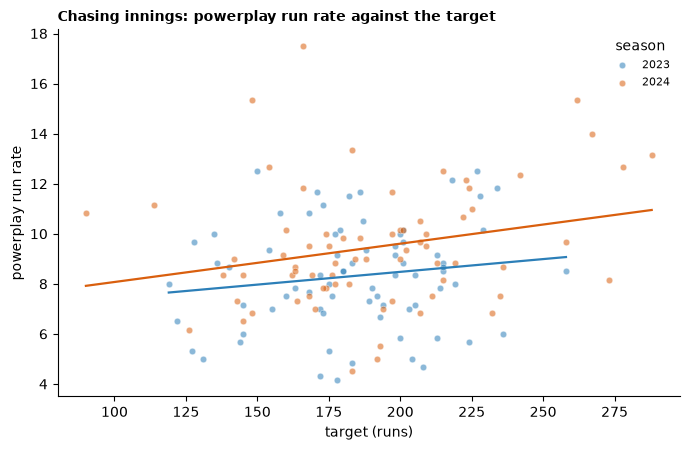

In [13]:
for metric, unit in (("attempt_share", "powerplay attempt share"), ("gear_up", "powerplay gear-up (runs per over)"),
                     ("pp_run_rate", "powerplay run rate")):
    fig = ctr.plot_target_response(chases, metric, unit, f"Chasing innings: {unit} against the target")
    results_io.write_figure(fig, settings, ANALYSIS, f"chase_{metric}_vs_target", SEED, PRODUCER)
    plt.show()

## Does the target explain the chase, later in the innings?

The same target model for the middle and death overs of chasing innings: one row per chase with at least 12 legal balls in the phase, attempt share and run rate in the phase, and at the death the gear-up over the same innings' middle overs. A chase that ended before the phase is absent, so the share of chases reaching each phase per season comes first; that is selection on match state, and it is why the death rows compare a more selected set. Binned read by target band, then the model.

In [14]:
later_rows, later_binned, reach = [], [], []
for phase_name in ("middle", "death"):
    phase_chases = ctr.chase_phase_table(df, settings, phase_name)
    phase_response = ctr.phase_target_response(phase_chases, settings, SEED, N_ITER)
    later_rows.append(phase_response["coefficients"])
    b = ctr.binned_by_target(phase_chases); b.insert(0, "phase", phase_name); later_binned.append(b)
    reach.append({"phase": phase_name, **{f"chases_{k}": v for k, v in phase_response["chases_by_season"].items()},
                  **{f"reached_{k}": round(v, 3) for k, v in phase_response["reach_by_season"].items()}})
later_response = pd.concat(later_rows, ignore_index=True)
later_binned = pd.concat(later_binned, ignore_index=True)
reach = pd.DataFrame(reach)
results_io.write_table(later_response, settings, ANALYSIS, "chase_target_response_middle_death", SEED, PRODUCER, EXTRA)
results_io.write_table(later_binned, settings, ANALYSIS, "chase_by_target_band_middle_death", SEED, PRODUCER, EXTRA)
results_io.write_table(reach, settings, ANALYSIS, "chase_phase_reach", SEED, PRODUCER, EXTRA)
display(reach)
display(later_binned.round(3))
later_response.round(4)

,phase,chases_2023,chases_2024,reached_2023,reached_2024
0,middle,73,71,1.000,1.000
1,death,73,71,0.863,0.817


,phase,season,target_band,innings,mean_target,attempt_share,run_rate,gear_up
0,middle,2023,under 160,15,139.267,0.123,6.793,NaN
1,middle,2023,160 to 189,26,176.462,0.169,7.808,NaN
2,middle,2023,190 and over,32,210.906,0.214,9.174,NaN
3,middle,2024,under 160,12,137.667,0.146,7.275,NaN
4,middle,2024,160 to 189,25,173.240,0.196,8.266,NaN
5,middle,2024,190 and over,34,222.059,0.210,9.363,NaN
6,death,2023,under 160,12,141.500,0.238,7.466,1.160
7,death,2023,160 to 189,21,176.571,0.275,10.045,2.441
8,death,2023,190 and over,30,211.900,0.299,9.524,0.421
9,death,2024,under 160,6,143.500,0.270,9.485,2.893


,phase,metric,term,estimate,ci_low,ci_high,p_positive,n_innings,target_centre
0,middle,attempt_share,intercept_at_180,0.1748,0.1597,0.1910,1.0000,144,180.0
1,middle,attempt_share,per_run_of_target,0.0012,0.0007,0.0016,1.0000,144,180.0
2,middle,attempt_share,season_difference_at_180,0.0138,-0.0121,0.0385,0.8523,144,180.0
3,middle,attempt_share,change_in_target_response,-0.0006,-0.0013,0.0000,0.0335,144,180.0
4,middle,attempt_share,raw_season_difference,0.0151,-0.0100,0.0407,0.8771,144,180.0
5,middle,run_rate,intercept_at_180,8.0672,7.6560,8.4799,1.0000,144,180.0
6,middle,run_rate,per_run_of_target,0.0334,0.0202,0.0474,1.0000,144,180.0
7,middle,run_rate,season_difference_at_180,0.3366,-0.3051,0.9899,0.8409,144,180.0
8,middle,run_rate,change_in_target_response,-0.0127,-0.0304,0.0044,0.0717,144,180.0
9,middle,run_rate,raw_season_difference,0.4256,-0.2644,1.0996,0.8915,144,180.0


Later in the chase the target does the work the powerplay result said it did not. In the middle overs every chase is present, and the middle-overs run rate responds to the target at 0.033 runs per over per run of target (interval +0.020 to +0.047, so a 50-run bigger target is worth 1.7 runs per over); the raw season difference of +0.43 shrinks to +0.34 at a common target (interval −0.31 to +0.99), and attempt share rises with the target at the same rate in both seasons. At the death, reached by 86% of 2023 chases and 82% of 2024 chases (faster finishes), run rate rose +0.76 raw and +0.65 at a common target (interval −0.41 to +1.66), and attempt share +2.9 points raw, +3.7 adjusted, both directional. Gear-up at the death falls with the target (−0.023 per run, clears) for the reason seen in the powerplay: a big chase keeps the middle overs fast.

So the picture across the chase is layered. In the powerplay the 2024 side went harder at every target, a change of approach the target does not explain. In the middle overs the target is the main driver and the season adds little once it is held fixed. At the death the season effect is directional on a selected population. The chase-side aggression that rose in 2024 was front-loaded: decided in the powerplay, not forced by the scoreboard.

The warm-up is real, unchanged across seasons, and not the 2024 story. The 2024 change is batting-first sides using the substitute as a twelfth batter mid-innings, some overs after a dismissal, led by Sunrisers and the aggressive wing; their elevens became more balanced, not more batting-heavy; the added batter mostly did not bat and batted slowly when he did; and swap innings scored less at the death, not more. Batting first did not show as a more aggressive powerplay; chasing sides were the more aggressive in 2024, at every target, so that is a change of approach rather than a response to bigger totals, and it was front-loaded: later in the chase the target, not the season, drives the middle-overs rate, and the death effect is directional on the chases that got there. The impact substitute changed selection and in-innings management in 2024 as insurance for the batting innings, and the powerplay aggression that rose in 2024 rose in the chase.